# Sea Ice Volume, Thickness, Freeboard and Snow

- Sea ice and snow volume compared with ACCESS-OM2
- Sea ice volume and winter thickness compared with satellite radar altimetry observations (Bocquet et al., 2024)
- Total freeboard compared with ICESat-2 laser altimetry (ATL20) and Bocquet et al. (2024), with ice and snow thickness for context

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
if not papermill: 
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)

In [3]:
import os
import glob
import xarray as xr
import numpy as np
import cf_xarray
from datetime import timedelta
import intake
import cartopy.crs as ccrs
import cmocean.cm as cmo
import xesmf
from scipy.ndimage import distance_transform_edt
import matplotlib.pyplot as plt
from distributed import Client

from exptdata_access import get_exptname_from_path

import pandas as pd
pd.set_option('display.max_rows', 500)

In [4]:
IAF = esm_file.find('iaf') > 0
IAF

True

In [5]:
if IAF:
    om2_exp = '025deg_jra55_iaf_omip2_cycle1'
else:
    om2_exp = '025deg_jra55_ryf9091_gadi'

In [6]:
client = Client(threads_per_worker=1)
client.dashboard_link

'/proxy/8787/status'

2026-10-30 14:46:19,224 - bokeh.server.protocol_handler - ERROR - error handling message
 message: Message 'PATCH-DOC' content: {'events': [{'kind': 'ModelChanged', 'model': {'id': 'p1080'}, 'attr': 'start', 'new': 266619.6013393402}, {'kind': 'ModelChanged', 'model': {'id': 'p1080'}, 'attr': 'end', 'new': 270166.30173683167}]} 
 error: AssertionError()
Traceback (most recent call last):
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/bokeh/server/protocol_handler.py", line 94, in handle
    work = await handler(message, connection)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/bokeh/server/session.py", line 295, in patch
    return connection.session._handle_patch(message, connection)
           ^^^^^^^^^^^^^^^^^^
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/bokeh/server/connection.py", line 65, in ses

### Open the intake-esm datastore

In [7]:
COLUMNS_WITH_ITERABLES = [
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
]

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=COLUMNS_WITH_ITERABLES
)

### Load ACCESS-OM3 sea ice data

Load grid cell area from cice variable

In [8]:
# CICE static grid file: T-cell areas, land mask and lon/lat (TLON/TLAT coordinates)
grid = datastore.search(variable=["tarea", "tmask"], frequency="fx", realm="seaIce", path=".*output000.*").to_dask()

In [9]:
grid = grid.load()

In [10]:
variables = ["hi_m", "hs_m", "aice_m"] # ice vol per cell, snow vol per cell, ice area fraction
# ice freeboard, and ice / snow thickness over the ice-covered area where output, for the freeboard section
freeboard_variables = ["sifb_m", "sithick_m", "sisnthick_m"]
ds = datastore.search(variable=variables + freeboard_variables, frequency="1mon").to_dask(
    xarray_open_kwargs = dict(chunks={"ni": -1, "nj": -1}, # Good for spatial operations, but not temporal
                              decode_timedelta=True),
)


Load the same variables for other OM3 runs, to compare against the main experiment.

In [11]:
%%time
# Other OM3 runs to compare against the main experiment (esm_file)
compare_esm_files = [
    "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json",
    "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/datastore.json",
]

# label -> (monthly sea ice dataset, CICE grid) for each OM3 run, the main experiment first
run_datasets = {f"OM3 {get_exptname_from_path(esm_file)}": (ds, grid)}

for f in compare_esm_files:
    if f == esm_file:  # the main experiment is already included
        continue
    run_datastore = intake.open_esm_datastore(f, columns_with_iterables=COLUMNS_WITH_ITERABLES)
    run_ds = run_datastore.search(variable=variables + freeboard_variables, frequency="1mon").to_dask(
        xarray_open_kwargs=dict(chunks={"ni": -1, "nj": -1}, decode_timedelta=True),
    )
    # CICE static grid file: T-cell areas, land mask and lon/lat (TLON/TLAT coordinates)
    run_grid = run_datastore.search(variable=["tarea", "tmask"], frequency="fx", realm="seaIce", path=".*output000.*").to_dask().load()
    run_datasets[f"OM3 {get_exptname_from_path(f)}"] = (run_ds, run_grid)

CPU times: user 27.6 s, sys: 59 s, total: 1min 26s
Wall time: 1min 13s


Integrate terms (sea ice vol, snow vol, sea ice area) for both poles.

In [12]:
%%time
# label -> hemispheric totals for each OM3 run
antarctic_seaice, arctic_seaice = {}, {}
for label, (run_ds, run_grid) in run_datasets.items():
    weighted = run_ds[variables] * run_grid.tarea
    antarctic_seaice[label] = weighted.where(run_grid.TLAT < 0).sum(['nj','ni']).compute()
    arctic_seaice[label] = weighted.where(run_grid.TLAT > 0).sum(['nj','ni']).compute()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 10.94 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 10.94 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/cli

CPU times: user 1min 28s, sys: 1min 53s, total: 3min 21s
Wall time: 3min 6s


Global maximum ice and snow thickness

In [13]:
%%time
# label -> global maxima for each OM3 run
seaice_max = {label: run_ds[variables].max(['nj','ni']).compute() for label, (run_ds, run_grid) in run_datasets.items()}

CPU times: user 21.7 s, sys: 31.8 s, total: 53.5 s
Wall time: 47.8 s


### Load ACCESS-OM2

In [14]:
catalog = intake.cat.access_nri

Load grid cell area variable

In [15]:
static_om2 = xr.open_dataset(catalog[om2_exp].search(filename="ocean_grid.nc").df.loc[0, "path"]).drop_vars("time")

In [16]:
var = catalog[om2_exp].search(variable=variables,frequency="1mon")
var.esmcat.aggregation_control.groupby_attrs = ['frequency']  ## Not sure why I have to do this!!
ds_om2=var.to_dask(xarray_open_kwargs=dict(chunks={"time": -1},
                                                   decode_timedelta=True,), 
                           xarray_combine_by_coords_kwargs = dict( # These kwargs can make things faster
        compat="override", data_vars="minimal", coords="minimal",),                          
)

# shift time to correct for OM2 calendar strangeness
def shift_time(ds):
    ds["time"] = ds.time.to_pandas() - timedelta(minutes=1)
    return ds

ds_om2 = shift_time(ds_om2)

# give sea ice variables useful spatial coordinates
ds_om2.coords['ni'] = static_om2['xt_ocean'].values
ds_om2.coords['nj'] = static_om2['yt_ocean'].values
ds_om2['ni'].attrs = static_om2['xt_ocean'].attrs
ds_om2['nj'].attrs = static_om2['yt_ocean'].attrs
ds_om2 = ds_om2.rename(({ 'ni': 'xt_ocean', 'nj': 'yt_ocean'}))

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='hi_m' → variable=['hi_m','hi_m']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='hs_m' → variable=['hs_m','hs_m']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='aice_m' → variable=['aice_m','aice_m']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)


Integrate terms for both poles.

In [17]:
%%time
antarctic_seaice_om2 = (ds_om2 * static_om2['area_t']).sel(yt_ocean=slice(None, 0)).sum(['yt_ocean','xt_ocean']).compute()
arctic_seaice_om2 = (ds_om2 * static_om2['area_t']).sel(yt_ocean=slice(0, None)).sum(['yt_ocean','xt_ocean']).compute()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 9.57 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


CPU times: user 1min 50s, sys: 2min 2s, total: 3min 52s
Wall time: 3min 44s


Global maximum ice and snow thickness

In [18]:
%%time
seaice_max_om2 = ds_om2.max(['yt_ocean','xt_ocean']).compute()

CPU times: user 35.7 s, sys: 40.3 s, total: 1min 15s
Wall time: 1min 12s


In [19]:
om2label = f"OM2 {om2_exp}"

# Sea Ice Volume timeseries

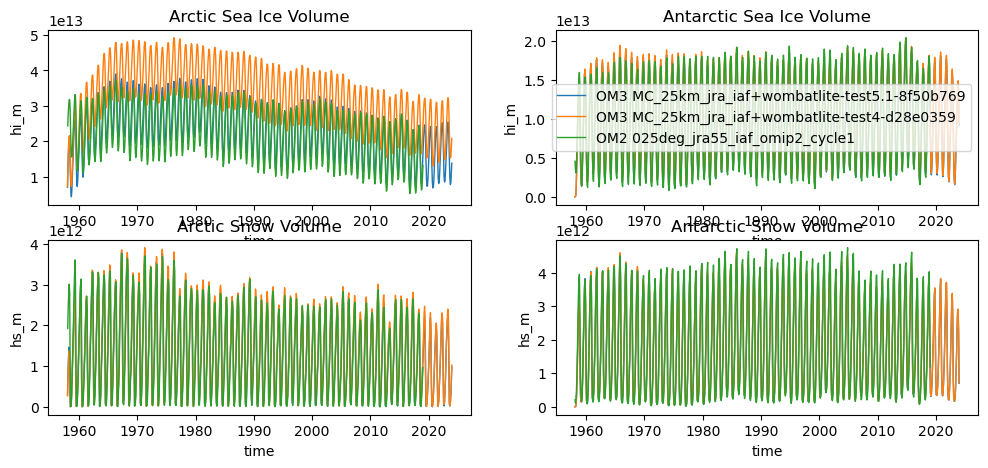

In [20]:
plt.figure(figsize=(12,5))

panels = [
    (1, arctic_seaice, arctic_seaice_om2, "hi_m", "Arctic Sea Ice Volume"),
    (2, antarctic_seaice, antarctic_seaice_om2, "hi_m", "Antarctic Sea Ice Volume"),
    (3, arctic_seaice, arctic_seaice_om2, "hs_m", "Arctic Snow Volume"),
    (4, antarctic_seaice, antarctic_seaice_om2, "hs_m", "Antarctic Snow Volume"),
]
for subplot, om3_totals, om2_totals, var, title in panels:
    plt.subplot(2,2,subplot)
    for label, totals in om3_totals.items():
        totals[var].plot(linewidth=1, label=label)
    om2_totals[var].plot(linewidth=1, label=om2label)
    plt.title(title)
    if subplot == 2:
        plt.legend()

mkmd.savefig(plt.gcf(),"Sea Ice and snow volume timeseries", "Sea Ice Volume timeseries for OM3 runs and ACCESS-OM2. [GitHub issue: Sea ice volume time series](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/20)", dpi=150)

# Sea ice maximum thickness timeseries

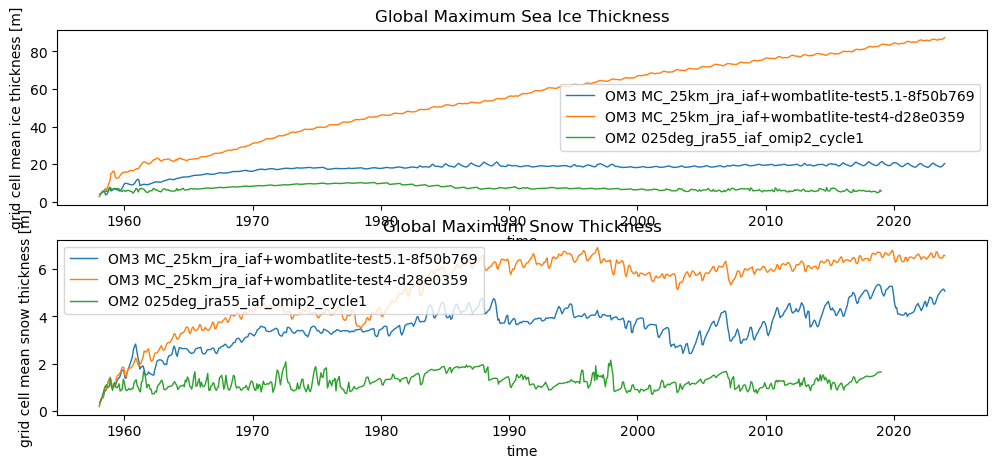

In [21]:
plt.figure(figsize=(12,5))

for subplot, var, title in [(1, "hi_m", "Global Maximum Sea Ice Thickness"), (2, "hs_m", "Global Maximum Snow Thickness")]:
    plt.subplot(2,1,subplot)
    for label, maxima in seaice_max.items():
        maxima[var].plot(linewidth=1, label=label)
    seaice_max_om2[var].plot(linewidth=1, label=om2label)
    plt.title(title)
    plt.ylabel(f"{ds[var].attrs['long_name']} [{ds[var].attrs['units']}]")
    plt.legend()

mkmd.savefig(plt.gcf(),"Sea Ice Volume: Maximum Thickness Timeseries", "Sea Ice maximum timeseries for OM3 runs and ACCESS-OM2. [GitHub issue: Sea ice thickness/concentration](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/22)", dpi=150)

# Comparison with satellite observations

Sea ice thickness observations are the [Bocquet et al. (2024)](https://doi.org/10.1029/2023JC020848) climate data record ([data](https://doi.org/10.5281/zenodo.12783561)), from radar altimetry on ERS-1, ERS-2, Envisat and CryoSat-2 (1994–2023), with the earlier missions calibrated against CryoSat-2. The Arctic record covers October to April only; the Antarctic record covers all months. Data are monthly on a 12.5 km equal-area grid for each hemisphere.

The observed `sea_ice_thickness` is the thickness of the ice-covered part of each grid cell, whereas the model `hi` is the grid-cell mean (volume per unit area), so observed thickness is multiplied by concentration to compare volumes. The record also includes the total and sea ice freeboards, used in the freeboard section below.

In [22]:
obs_dir = "/g/data/ik11/observations/bocquet2024"
obs_cell_area = 12500.0**2  # m^2, every cell of the equal-area grid is 12.5 km x 12.5 km

# Missions, newest to oldest
obs_sensors = ["c2esaD1", "env3", "ers2r", "ers1r"]

def load_bocquet(hemisphere):
    """Open the Bocquet et al. (2024) record for one hemisphere ('nh' or 'sh') as a single monthly timeseries.
    The dataset for each sensor is opened first, then the datasets are concatenated such that the newer mission is kept wherever two missions overlap.
    """
    merged_ds = None
    for sensor in obs_sensors:
        sensor_ds = xr.open_mfdataset(
            sorted(glob.glob(f"{obs_dir}/SIT_{hemisphere}_{sensor}_*.nc")),
            # lat/lon are dropped here and taken from a single file below as two 2002 Antarctic files (SIT_sh_ers2r_...)
            # store lon as (time, y, x), so lon would otherwise come out time-varying for the whole record.
            preprocess=lambda ds: ds[["sea_ice_thickness", "total_freeboard", "sea_ice_freeboard", "ice_concentration"]].drop_vars(["lat", "lon"]),
            combine="nested", concat_dim="time", data_vars="minimal", coords="minimal", compat="override", parallel=True,
        )
        if merged_ds is None:
            merged_ds = sensor_ds
        else:
            merged_ds = xr.concat([sensor_ds.sel(time=sensor_ds.time < merged_ds.time[0]), merged_ds], "time",
                               data_vars="minimal", coords="minimal", compat="override")
    # All missions share the same grid
    grid = xr.open_dataset(sorted(glob.glob(f"{obs_dir}/SIT_{hemisphere}_{obs_sensors[0]}_*.nc"))[0])
    return merged_ds.assign_coords(lat=grid.lat, lon=grid.lon)

bocquet = {"Arctic": load_bocquet("nh"), "Antarctic": load_bocquet("sh")}

## Sea ice volume

Volume is calculated on each dataset's own grid, following Bocquet et al. (2024): only cells with at least 50% ice concentration are included, between 50° and 81.5° latitude (81.5° is the limit of CryoSat-2 coverage) in each hemisphere.

Error bars on the observations are the 5th to 95th percentiles of the Bocquet et al. integrated volume ensemble ([data](https://doi.org/10.5281/zenodo.20525445)), which spans the snow depth, snow density and ice density products used to convert freeboard to thickness. Their volumes use a different mask to the one here, so the percentiles are applied relative to their median.

In [23]:
min_conc = 0.5
lat_range = {"Arctic": (50, 81.5), "Antarctic": (-81.5, -50)}

def masked_volume(thickness, conc, area, lat, region, dims):
    """Sea ice volume (m^3) from grid-cell-mean thickness, counting only cells with
    at least `min_conc` ice concentration within the region's `lat_range`"""
    lat_min, lat_max = lat_range[region]
    in_region = (conc >= min_conc) & (lat >= lat_min) & (lat <= lat_max)
    return (thickness * area).where(in_region).sum(dims, min_count=1)

# Ensemble statistics files of the Bocquet et al. integrated volumes for each mission, in the same order as obs_sensors
obs_volume_stats_files = {
    "Arctic": ["W99_STAT_c2esaD1.csv", "W99_STAT_env3.csv", "W99_STAT_ers2r.csv", "W99_STAT_ers1r.csv"],
    "Antarctic": ["STAT_c2esaDSH1_SARpIN.csv", "STAT_env3SH_corr.csv", "STAT_ers2rSH_corr.csv", "STAT_ers1rSH_corr.csv"],
}

def load_volume_uncertainty(region):
    """5th and 95th percentiles of the Bocquet et al. volume ensemble relative to its median, as a monthly
    timeseries, keeping the newer mission wherever two missions overlap"""
    merged = None
    for stats_file in obs_volume_stats_files[region]:
        stats = pd.read_csv(f"{obs_dir}/volumes/{stats_file}", index_col=0, parse_dates=["time"])
        # one row per statistic per month
        evolume = stats.pivot_table(index="time", columns=stats.index, values="evolume")
        relative = pd.DataFrame({"p05": evolume["5%"] / evolume["50%"], "p95": evolume["95%"] / evolume["50%"]})
        merged = relative if merged is None else pd.concat([relative[relative.index < merged.index[0]], merged])
    return merged.to_xarray()

In [24]:
%%time
obs_volume = {}
for region, obs_ds in bocquet.items():
    obs_conc = obs_ds.ice_concentration / 100  # percent -> fraction
    volume = masked_volume(obs_ds.sea_ice_thickness * obs_conc, obs_conc, obs_cell_area, obs_ds.lat, region, ["y", "x"]).compute()
    uncertainty = load_volume_uncertainty(region).reindex(time=volume.time)
    obs_volume[region] = xr.Dataset({"volume": volume, "p05": volume * uncertainty.p05, "p95": volume * uncertainty.p95})
    # sea ice area (m^2) over the same cells
    obs_volume[region]["area"] = masked_volume(obs_conc, obs_conc, obs_cell_area, obs_ds.lat, region, ["y", "x"]).compute()

# label -> {"Arctic": timeseries, "Antarctic": timeseries}, sea ice volume in m^3
model_volumes = {
    f"OM3 {get_exptname_from_path(esm_file)}": {
        region: masked_volume(ds.hi_m, ds.aice_m, grid.tarea, grid.TLAT, region, ["nj", "ni"]).compute()
        for region in lat_range
    }
}

# Sea ice area (m^2) over the same cells, for the main run
om3_area = {region: masked_volume(ds.aice_m, ds.aice_m, grid.tarea, grid.TLAT, region, ["nj", "ni"]).compute()
            for region in lat_range}

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 11.64 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 11.64 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/cli

CPU times: user 1min 1s, sys: 1min 16s, total: 2min 18s
Wall time: 2min 9s


Sea ice volume, calculated the same way, for other OM3 runs and ACCESS-OM2.

In [25]:
%%time
for label, (run_ds, run_grid) in run_datasets.items():
    if label in model_volumes:  # the main experiment is already included
        continue
    model_volumes[label] = {
        region: masked_volume(run_ds.hi_m, run_ds.aice_m, run_grid.tarea, run_grid.TLAT, region, ["nj", "ni"]).compute()
        for region in lat_range
    }

model_volumes[f"OM2 {om2_exp}"] = {
    region: masked_volume(ds_om2.hi_m, ds_om2.aice_m, static_om2.area_t, static_om2.geolat_t, region, ["yt_ocean", "xt_ocean"]).compute()
    for region in lat_range
}

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 17.98 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 17.98 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/cli

CPU times: user 2min 2s, sys: 2min 16s, total: 4min 18s
Wall time: 4min 7s


Climatologies are over the complete years of CryoSat-2 observations (2011–2022). For RYF runs the final decade of each model run is used instead.

In [26]:
obs_slice = slice("2011", "2022")

def clim_slice(da, t_slice=obs_slice):
    """Climatology period for a model run: the observation period `t_slice` for IAF, otherwise the run's final decade"""
    if IAF:
        return t_slice
    years = np.unique(da.time.dt.year)[-10:]
    return slice(str(years[0]), str(years[-1]))

def monthly_clim(da, t_slice):
    # reindex so months without observations leave gaps in the plotted line
    return da.sel(time=t_slice).groupby("time.month").mean("time").reindex(month=range(1, 13))

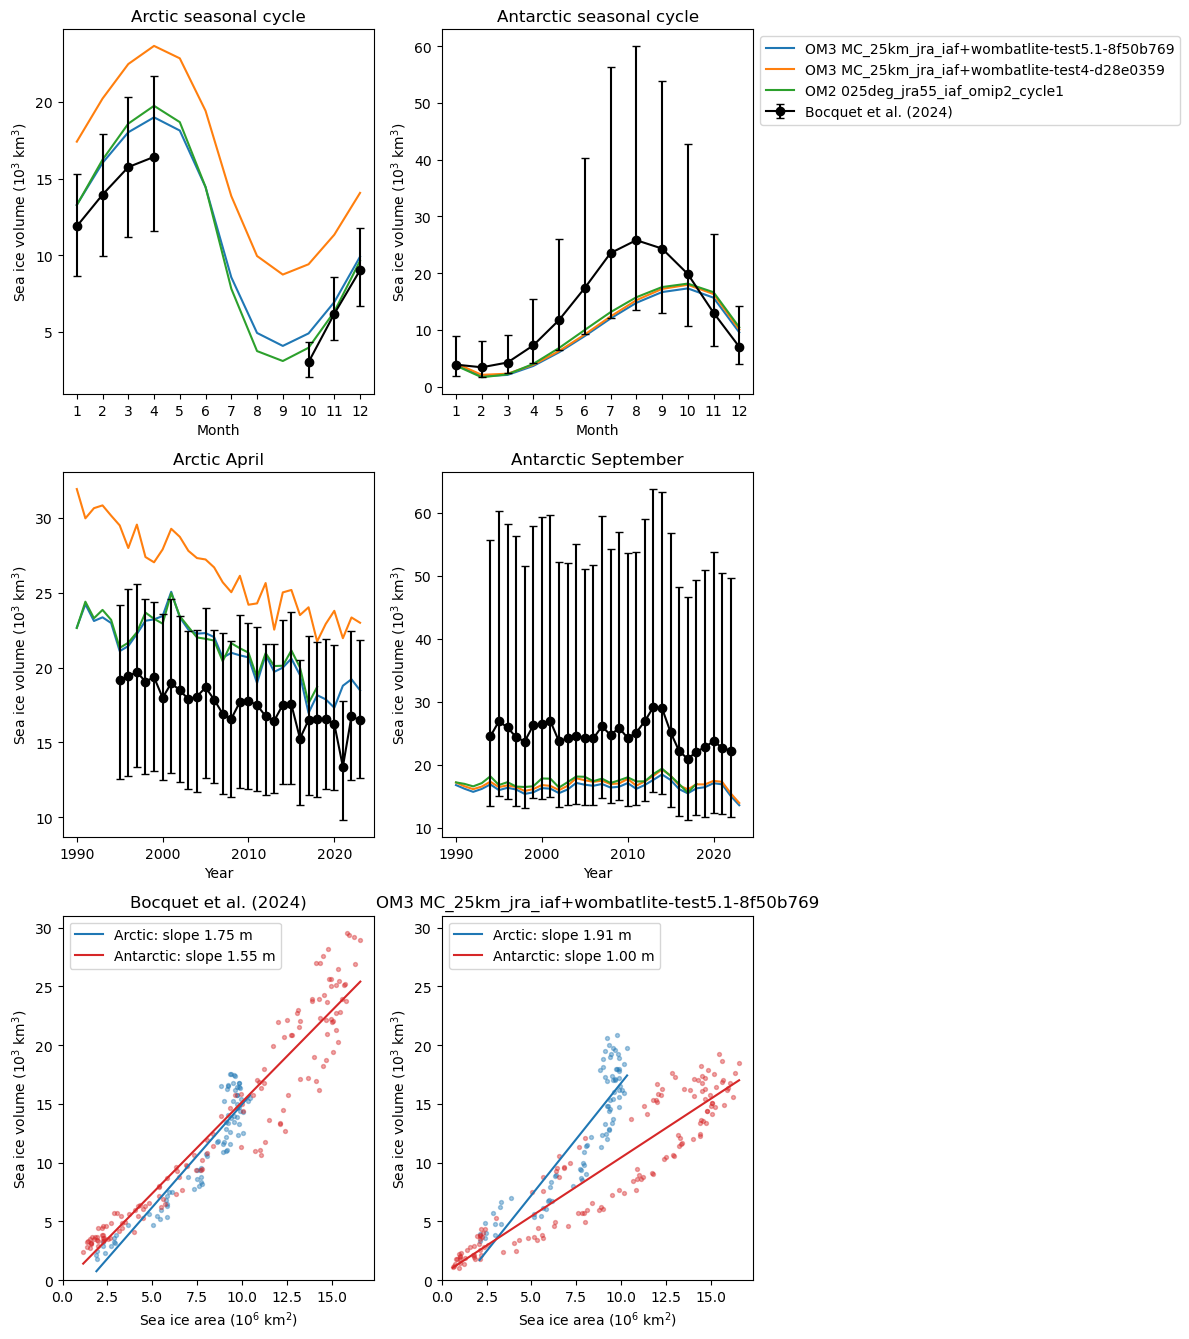

In [27]:
# Month of near-maximum volume in each hemisphere, for the interannual timeseries
peak_month = {"Arctic": 4, "Antarctic": 9}
month_names = {2: "February", 3: "March", 4: "April", 9: "September"}
obs_label = "Bocquet et al. (2024)"

def plot_obs(ax, obs_vol, x):
    """Observed volume (10^3 km^3) with 5-95% error bars"""
    obs_vol = obs_vol / 1e12  # m^3 -> 10^3 km^3
    ax.errorbar(obs_vol[x], obs_vol.volume, yerr=[obs_vol.volume - obs_vol.p05, obs_vol.p95 - obs_vol.volume],
                color="k", marker="o", capsize=3, label=obs_label)

nrows = (2 if IAF else 1) + 1  # plus a row of area vs volume scatter plots
fig, axes = plt.subplots(nrows, 2, figsize=(12, 4.5 * nrows), squeeze=False)

for col, region in enumerate(lat_range):
    # Seasonal cycle
    ax = axes[0, col]
    for label, volumes in model_volumes.items():
        vol = volumes[region]
        (monthly_clim(vol, clim_slice(vol)) / 1e12).plot(ax=ax, label=label)  # m^3 -> 10^3 km^3
    plot_obs(ax, monthly_clim(obs_volume[region], obs_slice), "month")
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("Month")
    ax.set_ylabel("Sea ice volume (10$^3$ km$^3$)")
    ax.set_title(f"{region} seasonal cycle")

    if not IAF:
        continue

    # Interannual timeseries of the near-maximum month
    ax = axes[1, col]
    month = peak_month[region]
    for label, volumes in model_volumes.items():
        vol = volumes[region].sel(time=slice("1990", None))
        (vol.sel(time=vol.time.dt.month == month).groupby("time.year").mean() / 1e12).plot(ax=ax, label=label)
    plot_obs(ax, obs_volume[region].sel(time=obs_volume[region].time.dt.month == month).groupby("time.year").mean(), "year")
    ax.set_xlabel("Year")
    ax.set_ylabel("Sea ice volume (10$^3$ km$^3$)")
    ax.set_title(f"{region} {month_names[month]}")

axes[0, 1].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Area vs volume, for the months of the year with observations
region_colors = {"Arctic": "tab:blue", "Antarctic": "tab:red"}

def scatter_with_fit(ax, area, volume, region):
    """Scatter of monthly volume (10^3 km^3) against area (10^6 km^2), with a least-squares line"""
    area, volume = area.values / 1e12, volume.values / 1e12  # m^2 -> 10^6 km^2, m^3 -> 10^3 km^3
    valid = np.isfinite(area) & np.isfinite(volume)
    area, volume = area[valid], volume[valid]
    ax.scatter(area, volume, s=8, alpha=0.4, color=region_colors[region])
    slope, intercept = np.polyfit(area, volume, 1)
    x = np.array([area.min(), area.max()])
    # 10^3 km^3 / 10^6 km^2 = 1 m, so the slope is a thickness in m
    ax.plot(x, slope * x + intercept, color=region_colors[region], label=f"{region}: slope {slope:.2f} m")

om3_main_label = next(iter(model_volumes))
for region in lat_range:
    obs_region = obs_volume[region].sel(time=obs_slice)
    scatter_with_fit(axes[-1, 0], obs_region.area, obs_region.volume, region)

    obs_months = np.unique(obs_region.volume.dropna("time").time.dt.month)
    vol = model_volumes[om3_main_label][region]
    vol = vol.sel(time=clim_slice(vol))
    vol = vol.sel(time=vol.time.dt.month.isin(obs_months))
    scatter_with_fit(axes[-1, 1], om3_area[region].sel(time=vol.time), vol, region)

for ax, title in zip(axes[-1], [obs_label, om3_main_label]):
    ax.set_xlabel("Sea ice area (10$^6$ km$^2$)")
    ax.set_ylabel("Sea ice volume (10$^3$ km$^3$)")
    ax.set_title(title)
    ax.legend(loc="upper left")
# same axes in both panels
for limits in ["xlim", "ylim"]:
    upper = max(getattr(ax, f"get_{limits}")()[1] for ax in axes[-1])
    for ax in axes[-1]:
        getattr(ax, f"set_{limits}")(0, upper)

fig.tight_layout()

mkmd.savefig(fig, "Sea Ice Volume compared with observations", "Sea ice volume (cells with at least 50% concentration, 50-81.5° latitude) for OM3 runs and ACCESS-OM2, compared with Bocquet et al. (2024) radar altimetry observations (error bars: 5-95% range of the observational volume ensemble). Top: seasonal cycle. Middle (IAF only): volume in the month of near-maximum volume. Bottom: monthly sea ice volume against sea ice area (over the same cells) for the observations and the main OM3 run, in the months of the year with observations, with least-squares lines (the slope is a mean thickness). [GitHub issue: Sea-Ice Volume and Thickness](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/48)", dpi=150)

## Sea ice thickness maps

End-of-winter (March in the Arctic, September in the Antarctic) and February climatological ice thickness compared with the observations. Thickness here is that of the ice-covered part of each cell (volume / concentration), matching the observed `sea_ice_thickness`, and is shown only where the climatological concentration is at least 50%.

The model climatology is regridded onto the observational grid with `xesmf` for these maps only; the volumes above use each dataset's native grid.

In [28]:
# Month of the year to map in each hemisphere: end of winter, and February
map_month = {"Arctic": 3, "Antarctic": 9}
february = {"Arctic": 2, "Antarctic": 2}
all_map_months = sorted(set(map_month.values()) | set(february.values()))

om3_clim = ds[["hi_m", "aice_m"]].sel(time=clim_slice(ds))
om3_clim = om3_clim.sel(time=om3_clim.time.dt.month.isin(all_map_months)).groupby("time.month").mean("time").compute()

In [29]:
def fill_nan_nearest(arr):
    """Fill NaNs with the value of the nearest non-NaN grid cell."""
    nan_mask = np.isnan(arr)
    nearest = distance_transform_edt(nan_mask, return_distances=False, return_indices=True)
    return arr[tuple(nearest)]

# Native model grid (tripole) coordinates and land mask, from the CICE grid file, for regridding
# here and for the freeboard maps below.
# TLON/TLAT are NaN wherever tmask is NaN (masked-out cells); those points are
# excluded from regridding via the mask below, but xesmf still needs a valid
# position for every grid point (NaN coordinates corrupt the weights of nearby
# valid cells), so fill with the nearest defined neighbour (as in SeaIce_area.ipynb).
native_mask = np.nan_to_num(grid.tmask.values, nan=0.0).astype(int)
# ESMF's bilinear stencil search is unreliable within ~0.5 deg of the true pole
# (see SeaIce_area.ipynb), so drop the few cells there.
native_mask[grid.TLAT.values > 89.5] = 0

native_grid = xr.Dataset(coords={
    "lon": (("nj", "ni"), fill_nan_nearest(grid.TLON.values)),
    "lat": (("nj", "ni"), fill_nan_nearest(grid.TLAT.values)),
})
native_grid["mask"] = (("nj", "ni"), native_mask)

bocquet_regridders = {
    region: xesmf.Regridder(native_grid, xr.Dataset(coords={"lon": obs_ds.lon, "lat": obs_ds.lat}),
                            method="bilinear", periodic=True, ignore_degenerate=True)
    for region, obs_ds in bocquet.items()
}

In [30]:
def thickness_maps(months):
    """Climatological thickness of the ice-covered part of each cell, where concentration >= min_conc, for the
    month of the year given for each hemisphere in `months`: OM3 regridded onto the Bocquet et al. grid, and Bocquet et al."""
    om3_thickness, bocquet_thickness = {}, {}
    for region, obs_ds in bocquet.items():
        month_clim = om3_clim[["hi_m", "aice_m"]].sel(month=months[region])
        rg = bocquet_regridders[region](month_clim).assign_coords(x=obs_ds.x, y=obs_ds.y).compute()
        om3_thickness[region] = (rg.hi_m / rg.aice_m).where(rg.aice_m >= min_conc)

        obs_month = obs_ds.sel(time=obs_slice)
        obs_month = obs_month.sel(time=obs_month.time.dt.month == months[region])
        obs_conc = obs_month.ice_concentration.mean("time") / 100
        bocquet_thickness[region] = obs_month.sea_ice_thickness.mean("time").where(obs_conc >= min_conc).compute()
    return om3_thickness, bocquet_thickness

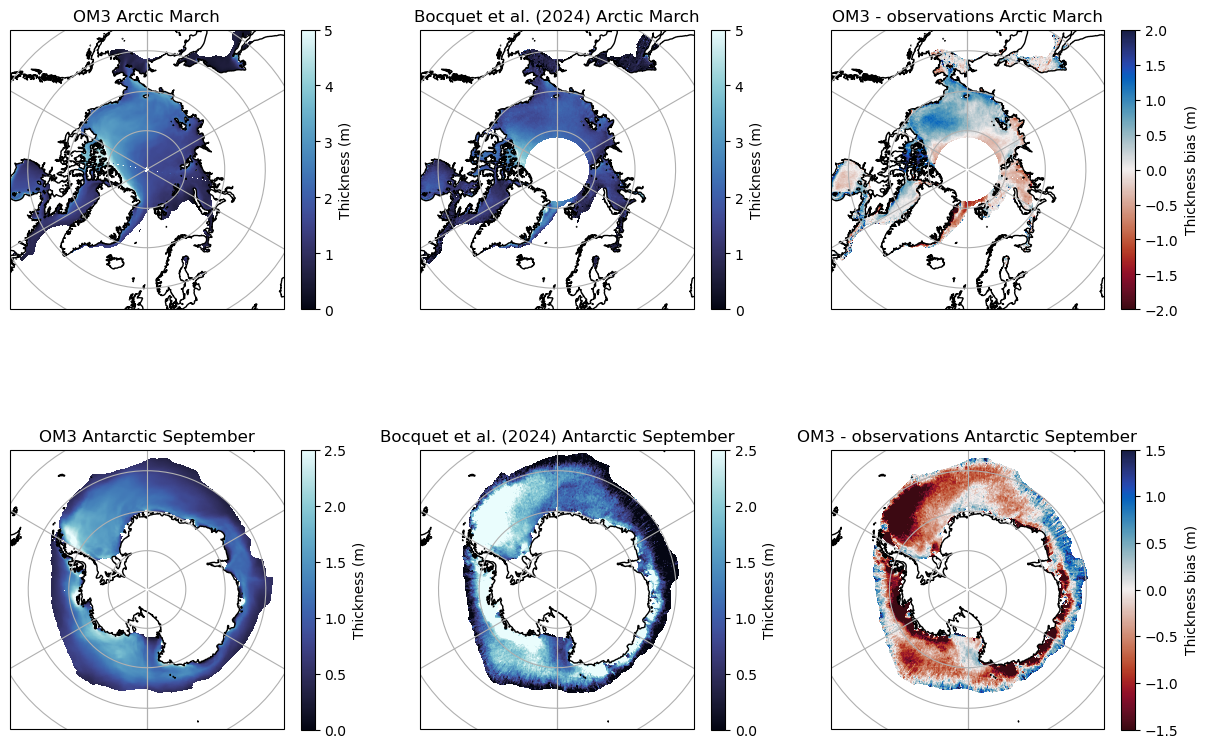

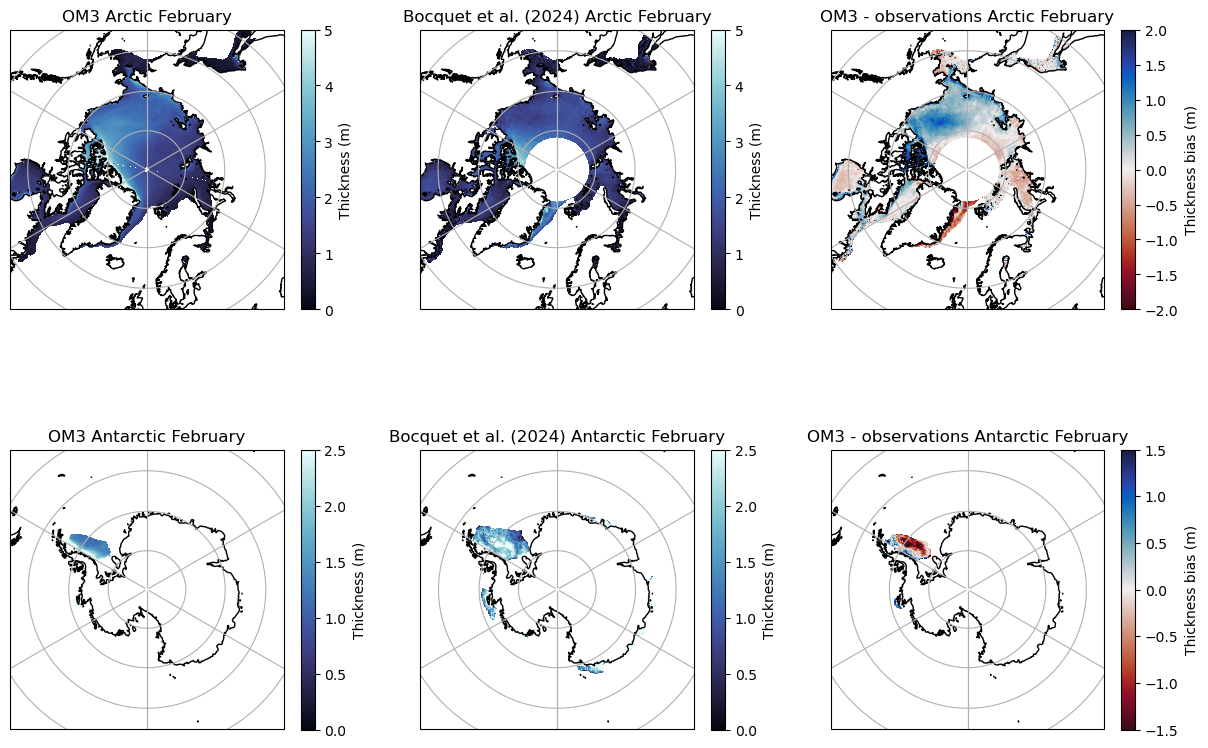

In [31]:
def bocquet_crs(obs_ds):
    """Lambert azimuthal equal-area projection of the observational grid"""
    return ccrs.LambertAzimuthalEqualArea(central_latitude=obs_ds.attrs["lat_0"], central_longitude=obs_ds.attrs["lon_0"])

# The observational x/y are measured from the corner of the grid rather than the pole
def bocquet_xy(obs_ds):
    return obs_ds.x - obs_ds.attrs["width"] / 2, obs_ds.y - obs_ds.attrs["height"] / 2

map_settings = {
    "Arctic": dict(projection=ccrs.NorthPolarStereo(), extent=[-180, 180, 55, 90], vmax=5, bias=2),
    "Antarctic": dict(projection=ccrs.SouthPolarStereo(), extent=[-180, 180, -90, -55], vmax=2.5, bias=1.5),
}

def plot_thickness_maps(months):
    """OM3, Bocquet et al. and OM3 - Bocquet et al. thickness for the month of the year given for each hemisphere in `months`"""
    om3_thickness, bocquet_thickness = thickness_maps(months)
    fig = plt.figure(figsize=(15, 10))

    for row, region in enumerate(lat_range):
        settings = map_settings[region]
        crs = bocquet_crs(bocquet[region])
        x, y = bocquet_xy(bocquet[region])
        month = month_names[months[region]]
        panels = [
            (om3_thickness[region], f"OM3 {region} {month}", cmo.ice, 0, settings["vmax"], "Thickness (m)"),
            (bocquet_thickness[region], f"Bocquet et al. (2024) {region} {month}", cmo.ice, 0, settings["vmax"], "Thickness (m)"),
            (om3_thickness[region] - bocquet_thickness[region], f"OM3 - observations {region} {month}", cmo.balance_r, -settings["bias"], settings["bias"], "Thickness bias (m)"),
        ]
        for col, (data, title, cmap, vmin, vmax, cbar_label) in enumerate(panels):
            ax = fig.add_subplot(2, 3, 3 * row + col + 1, projection=settings["projection"])
            im = ax.pcolormesh(x, y, data, transform=crs, cmap=cmap, vmin=vmin, vmax=vmax)
            ax.set_extent(settings["extent"], ccrs.PlateCarree())
            ax.coastlines()
            ax.gridlines()
            ax.set_title(title)
            plt.colorbar(im, ax=ax, shrink=0.8, label=cbar_label)

    when = f"{month_names[months['Arctic']]} (Arctic) and {month_names[months['Antarctic']]} (Antarctic)"
    mkmd.savefig(fig, f"{month_names[months['Arctic']]} / {month_names[months['Antarctic']]} Sea Ice Thickness compared with observations", f"Climatological {when} sea ice thickness (ice-covered part of each cell, where concentration is at least 50%) for OM3 ({clim_slice(ds).start}-{clim_slice(ds).stop}) and Bocquet et al. (2024) radar altimetry observations ({obs_slice.start}-{obs_slice.stop}), and their difference. [GitHub issue: Sea-Ice Volume and Thickness](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/48)", dpi=150)
    plt.show()

plot_thickness_maps(map_month)
plot_thickness_maps(february)

# Sea ice freeboard

Total (snow + ice) sea ice freeboard compared with ICESat-2 laser altimetry: the ATL20 monthly gridded freeboard product ([Petty et al.](https://doi.org/10.5067/ATLAS/ATL20.005), V005, October 2018 onwards). ICESat-2's laser reflects from the snow surface, so ATL20 is the height of the snow surface above local sea level, averaged over the ice-covered part of each 25 km grid cell. Mean total freeboard, ice thickness and snow thickness are also compared with Bocquet et al. (2024) (CryoSat-2 over this period), for context.

## Model freeboard

CICE's `sifb` is the ice freeboard (height of the ice surface above sea level, zero where the ice is flooded), averaged over the ice-covered part of each cell. Total freeboard adds the snow depth over the same ice-covered area: `sisnthick` where it is output, otherwise `hs` (a grid-cell mean) divided by `aice`. Only cells with at least 50% ice concentration are used, as ATL20 freeboards come only from ice-covered segments.

Ice thickness is likewise over the ice-covered part of each cell: `sithick` where it is output, otherwise `hi` (a grid-cell mean) divided by `aice`.

In [32]:
def freeboard_thickness_snow(run_ds):
    """Monthly total freeboard, ice thickness and snow thickness (m) over the ice-covered part of each cell,
    from one OM3 run's monthly sea ice data"""
    if "sisnthick_m" in run_ds:
        snow = run_ds.sisnthick_m
    else:
        snow = run_ds.hs_m / run_ds.aice_m
    snow = snow.where(run_ds.aice_m >= min_conc)
    freeboard = run_ds.sifb_m.where(run_ds.aice_m >= min_conc) + snow

    if "sithick_m" in run_ds:
        thickness = run_ds.sithick_m
    else:
        thickness = run_ds.hi_m / run_ds.aice_m
    thickness = thickness.where(run_ds.aice_m >= min_conc)

    return freeboard, thickness, snow

## ICESat-2 observations

ATL20 monthly mean freeboard (`monthly/mean_fb`) on the NSIDC 25 km polar stereographic grids, with the matching NSIDC grid cell areas.

In [33]:
atl20_dir = "/g/data/ik11/observations/icesat2_atl20/V005"

def load_atl20(hemisphere):
    """Monthly ATL20 freeboard (m) for one hemisphere ('NH' or 'SH') as an xarray Dataset"""
    files = sorted(glob.glob(f"{atl20_dir}/{hemisphere}/ATL20-*.h5"))

    def add_time(ds):
        # one month per file; label it mid-month, from the time of its first freeboard segment
        start = pd.Timestamp(ds.delta_time_beg.values[0])
        return ds[["mean_fb"]].expand_dims(time=[pd.Timestamp(f"{start:%Y-%m}-15")])

    # the files are netCDF-4 compatible HDF5: monthly fields in the "monthly" group,
    # grid coordinates in the root group
    ds = xr.open_mfdataset(files, group="monthly", preprocess=add_time,
                           combine="nested", concat_dim="time", parallel=True)
    atl20_grid = xr.open_dataset(files[0])
    return ds.rename(mean_fb="freeboard", grid_y="y", grid_x="x").assign_coords(
        y=atl20_grid.grid_y.values,
        x=atl20_grid.grid_x.values,
        lat=(("y", "x"), atl20_grid.grid_lat.values),
        lon=(("y", "x"), atl20_grid.grid_lon.values),
    )

atl20 = {"Arctic": load_atl20("NH"), "Antarctic": load_atl20("SH")}

In [34]:
def add_nsidc_areas(filename, obs_ds):
    """
    Load the unformatted binary file with grid areas from NSIDC, and add as a coordinate to an xarray dataset
    """
    # ATL20 uses the same 25 km polar-stereographic grids as the NSIDC sea ice concentration CDR;
    # values are stored as integer km^2 * 1000
    areas = np.fromfile(filename, dtype=np.int32).reshape(obs_ds.lat.shape)
    return obs_ds.assign_coords(area=(("y", "x"), areas * 1e3))  # convert to m^2

atl20["Arctic"] = add_nsidc_areas("/g/data/av17/access-nri/OM3/CDR_G02202_V5/NSIDC-G02202-nh/psn25area_v3.dat", atl20["Arctic"])
atl20["Antarctic"] = add_nsidc_areas("/g/data/av17/access-nri/OM3/CDR_G02202_V5/NSIDC-G02202-sh/pss25area_v3.dat", atl20["Antarctic"])

## Regional means

Mean freeboard over each hemisphere's ice-covered cells (area weighted), equatorward of ICESat-2's orbital limit of 88°. Ice and snow thickness, and the Bocquet et al. freeboard, are averaged between 50° and 81.5° latitude (the Bocquet et al. coverage), so the Arctic Bocquet et al. freeboard misses the thick ice north of 81.5°. Bocquet et al. derive thickness and both freeboards from the radar freeboard using an ensemble of snow depth and density products, so their snow thickness (`total_freeboard - sea_ice_freeboard`) comes from those snow products, not observations.

In [35]:
atl20_lat_range = {"Arctic": (0, 88), "Antarctic": (-88, 0)}

def regional_mean(da, area, lat, region, dims, lat_bounds):
    """Area-weighted mean over cells with data within the region's `lat_bounds`"""
    lat_min, lat_max = lat_bounds[region]
    da = da.where((lat >= lat_min) & (lat <= lat_max))
    return da.weighted(area.fillna(0)).mean(dims)

In [36]:
%%time
# label -> native monthly freeboard, for sampling like ATL20 below
run_freeboards = {}

# label -> {"Arctic": timeseries, "Antarctic": timeseries}, regional means in m
model_freeboards, model_thicknesses, model_snows = {}, {}, {}

def add_run(label, run_ds, run_grid):
    """Add one OM3 run's regional mean freeboard, ice thickness and snow thickness"""
    run_freeboard, run_thickness, run_snow = freeboard_thickness_snow(run_ds)
    area, lat = run_grid.tarea, run_grid.TLAT
    run_freeboards[label] = run_freeboard
    model_freeboards[label] = {region: regional_mean(run_freeboard, area, lat, region, ["nj", "ni"], atl20_lat_range).compute()
                               for region in lat_range}
    model_thicknesses[label] = {region: regional_mean(run_thickness, area, lat, region, ["nj", "ni"], lat_range).compute()
                                for region in lat_range}
    model_snows[label] = {region: regional_mean(run_snow, area, lat, region, ["nj", "ni"], lat_range).compute()
                          for region in lat_range}

# The OM3 runs loaded above: the main experiment and those in compare_esm_files (ACCESS-OM2 does not output sifb)
for label, (run_ds, run_grid) in run_datasets.items():
    add_run(label, run_ds, run_grid)

atl20_freeboards = {region: regional_mean(obs_ds.freeboard, obs_ds.area, obs_ds.lat, region, ["y", "x"], atl20_lat_range)
                    for region, obs_ds in atl20.items()}

bocquet_thicknesses, bocquet_freeboards, bocquet_snows = {}, {}, {}
for region, obs_ds in bocquet.items():
    obs_ds = obs_ds.sel(time=slice("2018-10", None))  # the ICESat-2 period
    obs_ds = obs_ds.where(obs_ds.ice_concentration / 100 >= min_conc)
    obs_ds["snow"] = obs_ds.total_freeboard - obs_ds.sea_ice_freeboard
    means = regional_mean(
        obs_ds[["sea_ice_thickness", "total_freeboard", "snow"]], xr.full_like(obs_ds.lat, obs_cell_area), obs_ds.lat,
        region, ["y", "x"], lat_range
    ).compute()
    bocquet_thicknesses[region] = means.sea_ice_thickness
    bocquet_freeboards[region] = means.total_freeboard
    bocquet_snows[region] = means.snow

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 10.85 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
 

CPU times: user 4min, sys: 4min 38s, total: 8min 39s
Wall time: 8min 5s


Climatologies are over the complete years of ATL20 observations overlapping the IAF runs (2019–2023). For RYF runs the final decade of each model run is used instead.

In [37]:
atl20_slice = slice("2019", "2023")

## Freeboard, thickness and snow plots

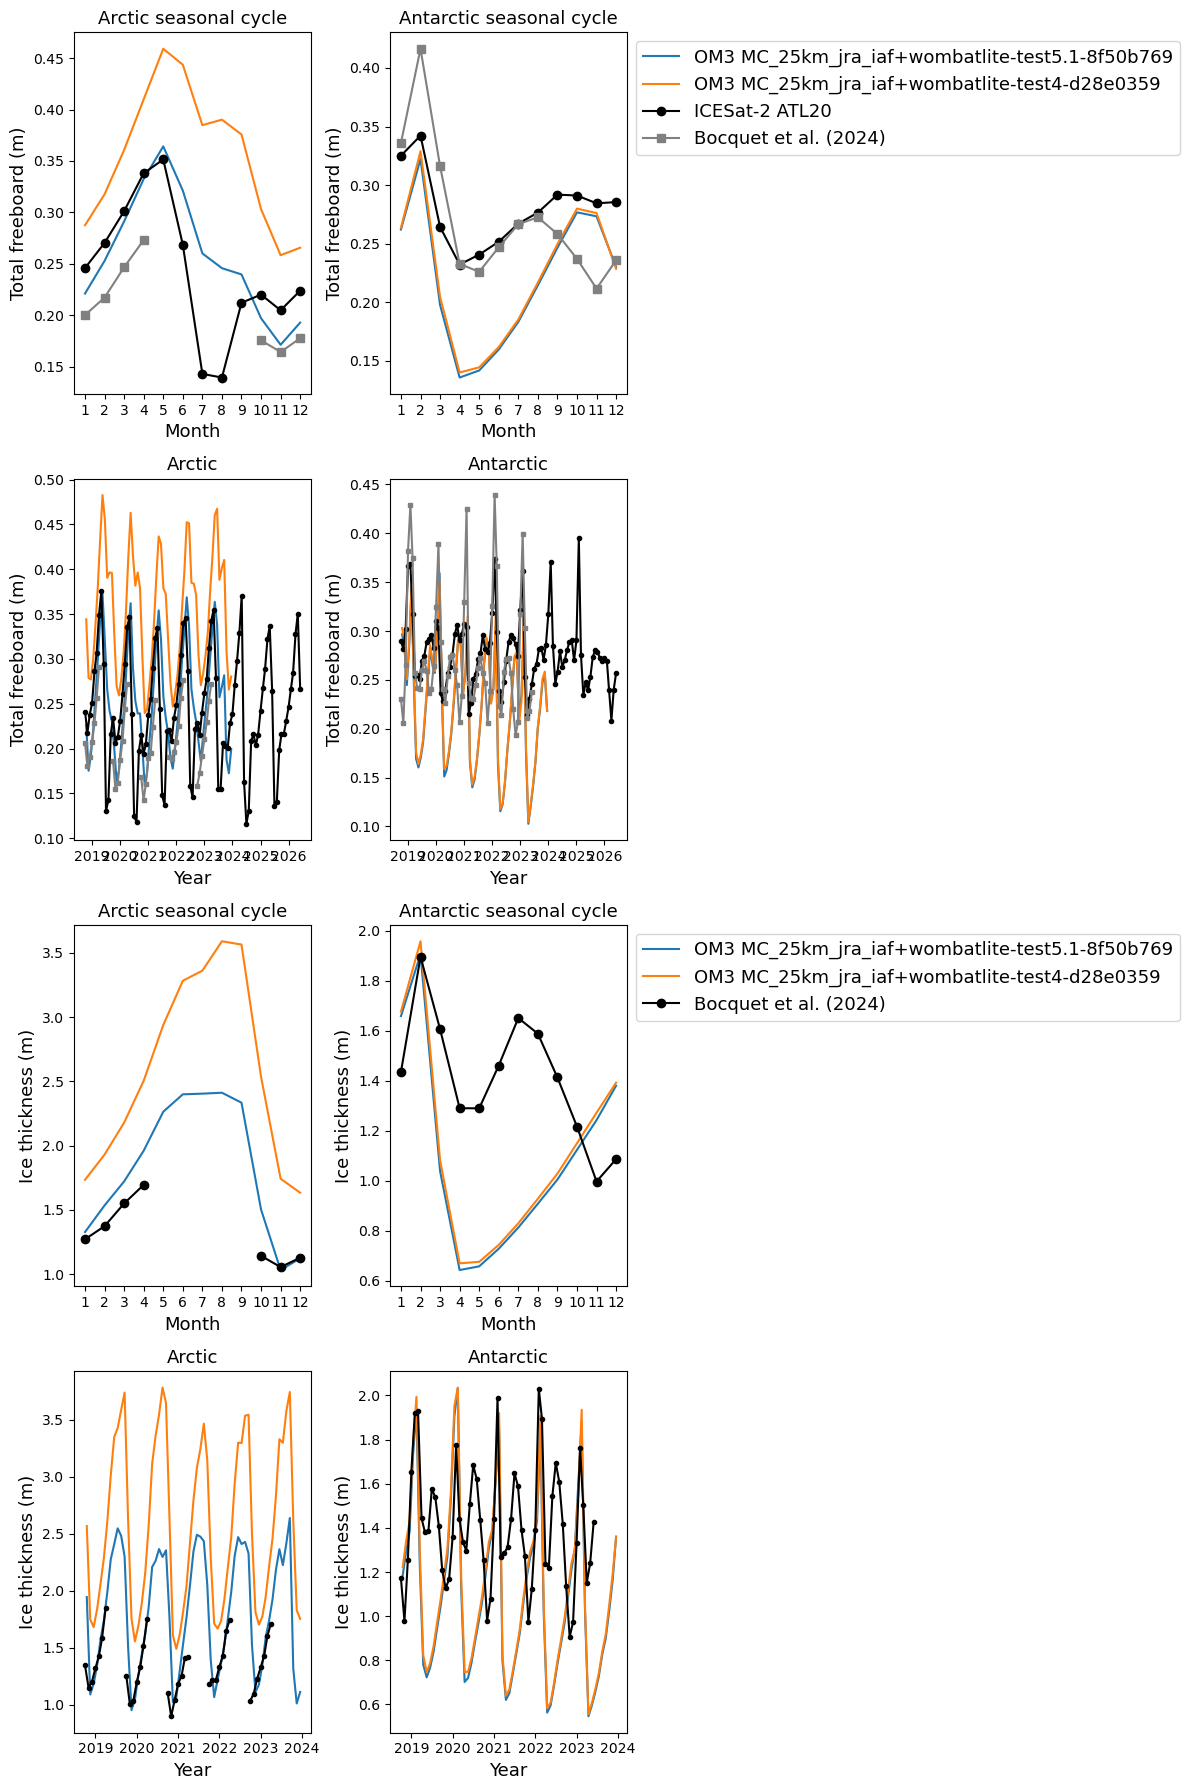

In [38]:
font = {'size': 13}

atl20_obs = (atl20_freeboards, "ICESat-2 ATL20", "k", "o")
bocquet_label = "Bocquet et al. (2024)"

def plot_means(variables, title, caption):
    """Seasonal cycle and (IAF only) monthly timeseries of regional means for each model run and the observations,
    for each of `variables`: a list of (model_means, observations, ylabel), where observations is a list of
    (obs_means, obs_label, color, marker)"""
    rows_per_variable = 2 if IAF else 1
    nrows = rows_per_variable * len(variables)
    fig, axes = plt.subplots(nrows, 2, figsize=(12, 4.5 * nrows), squeeze=False)

    for v, (model_means, observations, ylabel) in enumerate(variables):
        row = v * rows_per_variable
        for col, region in enumerate(lat_range):
            # Seasonal cycle
            ax = axes[row, col]
            for label, means in model_means.items():
                mean = means[region]
                monthly_clim(mean, clim_slice(mean, atl20_slice)).plot(ax=ax, label=label)
            for obs_means, obs_label, color, marker in observations:
                monthly_clim(obs_means[region], atl20_slice).plot(ax=ax, color=color, marker=marker, label=obs_label)
            ax.set_xticks(range(1, 13))
            ax.set_xlabel("Month", font)
            ax.set_ylabel(ylabel, font)
            ax.set_title(f"{region} seasonal cycle", font)

            if not IAF:
                continue

            # Monthly timeseries over the ICESat-2 period
            ax = axes[row + 1, col]
            for label, means in model_means.items():
                means[region].sel(time=slice("2018-10", None)).plot(ax=ax, label=label)
            for obs_means, obs_label, color, marker in observations:
                # resample to every month so months without observations leave gaps in the plotted line
                obs_means[region].sel(time=slice("2018-10", None)).resample(time="1MS").mean().plot(
                    ax=ax, color=color, marker=marker, markersize=3, label=obs_label)
            ax.set_xlabel("Year", font)
            ax.set_ylabel(ylabel, font)
            ax.set_title(region, font)

        # the observations differ between variables, so a legend for each
        axes[row, 1].legend(prop=font, loc="upper left", bbox_to_anchor=(1, 1))

    fig.tight_layout()

    mkmd.savefig(fig, title, caption, dpi=150)
    plt.show()

plot_means(
    [
        (model_freeboards, [atl20_obs, (bocquet_freeboards, bocquet_label, "0.5", "s")], "Total freeboard (m)"),
        (model_thicknesses, [(bocquet_thicknesses, bocquet_label, "k", "o")], "Ice thickness (m)"),
    ],
    "Sea Ice Freeboard and Thickness",
    "Mean total (snow + ice) freeboard compared with ICESat-2 ATL20 and Bocquet et al. (2024) CryoSat-2 observations (upper rows; the Bocquet et al. freeboard covers only 50-81.5° latitude), and mean ice thickness over the ice-covered part of each cell (50-81.5° latitude) compared with Bocquet et al. (2024) (lower rows), over cells with at least 50% ice concentration for OM3 runs. For each: seasonal cycle, then (IAF only) monthly timeseries. [GitHub issue: Sea-Ice Volume and Thickness](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/48)",
)

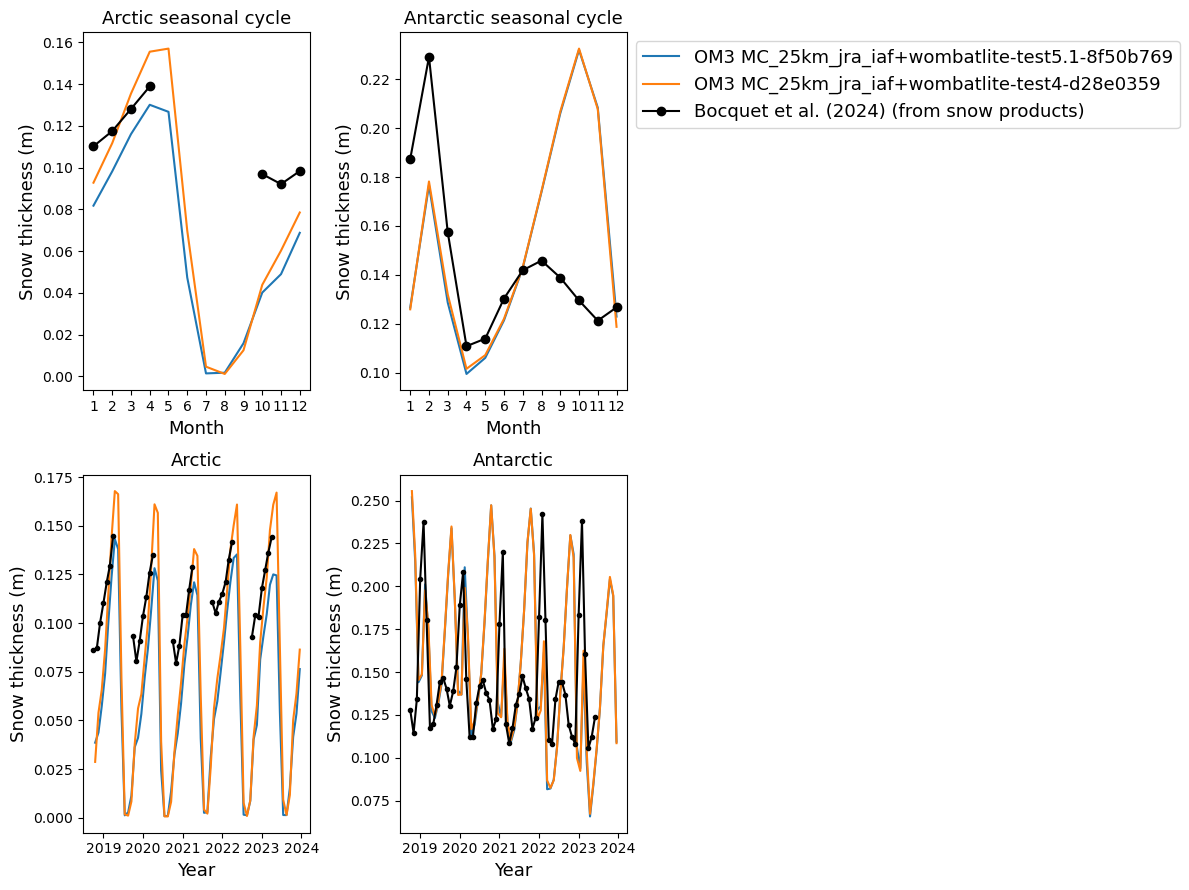

In [39]:
plot_means(
    [(model_snows, [(bocquet_snows, f"{bocquet_label} (from snow products)", "k", "o")], "Snow thickness (m)")],
    "Snow Thickness",
    "Mean snow thickness over the ice-covered part of cells with at least 50% ice concentration (50-81.5° latitude) for OM3 runs, compared with the snow thickness implied by Bocquet et al. (2024) (total minus sea ice freeboard), which comes from the snow depth products used in their retrieval, not observations. Top: seasonal cycle. Bottom (IAF only): monthly timeseries. [GitHub issue: Sea-Ice Volume and Thickness](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/48)",
)

## Freeboard maps

End-of-winter (March in the Arctic, September in the Antarctic) and February climatological total freeboard for the main OM3 run (regridded onto each hemisphere's ATL20 grid, using the native grid defined for the thickness maps above) and ATL20, and their difference. The same regridding is used below to sample each OM3 run like ATL20.

In [40]:
freeboard_main = run_freeboards[f"OM3 {get_exptname_from_path(esm_file)}"]
om3_fb_clim = freeboard_main.sel(time=clim_slice(freeboard_main, atl20_slice))
om3_fb_clim = om3_fb_clim.sel(time=om3_fb_clim.time.dt.month.isin(all_map_months)).groupby("time.month").mean("time").compute()

atl20_regridders = {
    region: xesmf.Regridder(native_grid, xr.Dataset(coords={"lon": obs_ds.lon, "lat": obs_ds.lat}),
                            method="bilinear", periodic=True, ignore_degenerate=True)
    for region, obs_ds in atl20.items()
}

def regrid_freeboard(fb, region):
    """Regrid model freeboard (NaN where there is none) onto the region's ATL20 grid"""
    # Regrid freeboard (zero where there is none), where the model has freeboard (concentration >= min_conc),
    # and a field of ones. Normalising freeboard by the regridded `has_fb` stops cells near the ice edge being
    # diluted by the zeros, and `has_fb / ones` is the fraction of each destination cell fed by model points with freeboard.
    has_fb = fb.notnull()
    native = xr.Dataset({"freeboard": fb.fillna(0), "has_fb": has_fb.astype(float), "ones": xr.ones_like(has_fb, dtype=float)})
    regridded = atl20_regridders[region](native)
    obs_ds = atl20[region]
    return (regridded.freeboard / regridded.has_fb).where(regridded.has_fb / regridded.ones > 0.5).assign_coords(x=obs_ds.x, y=obs_ds.y)

def freeboard_maps(months):
    """Climatological total freeboard for the month of the year given for each hemisphere in `months`:
    OM3 regridded onto the ATL20 grid, and ATL20"""
    om3_freeboard, atl20_freeboard = {}, {}
    for region, obs_ds in atl20.items():
        om3_freeboard[region] = regrid_freeboard(om3_fb_clim.sel(month=months[region]), region).compute()
        obs_month = obs_ds.freeboard.sel(time=atl20_slice)
        atl20_freeboard[region] = obs_month.sel(time=obs_month.time.dt.month == months[region]).mean("time").compute()
    return om3_freeboard, atl20_freeboard

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_c

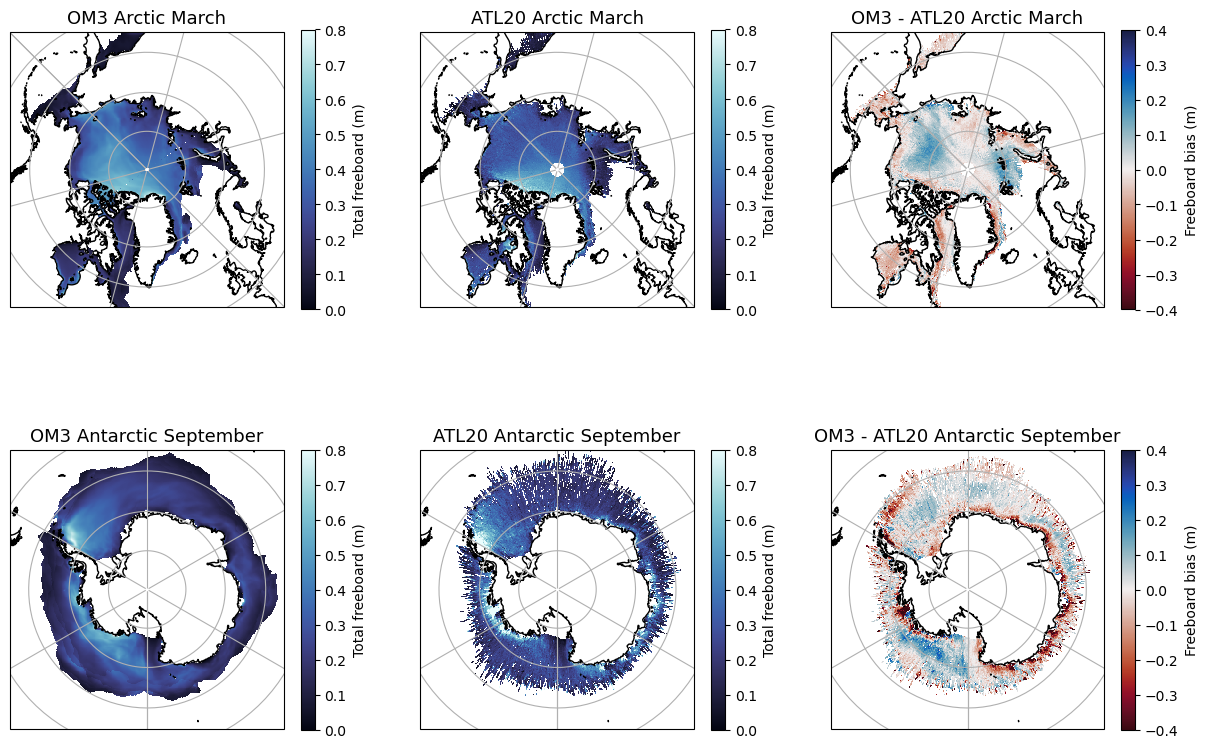

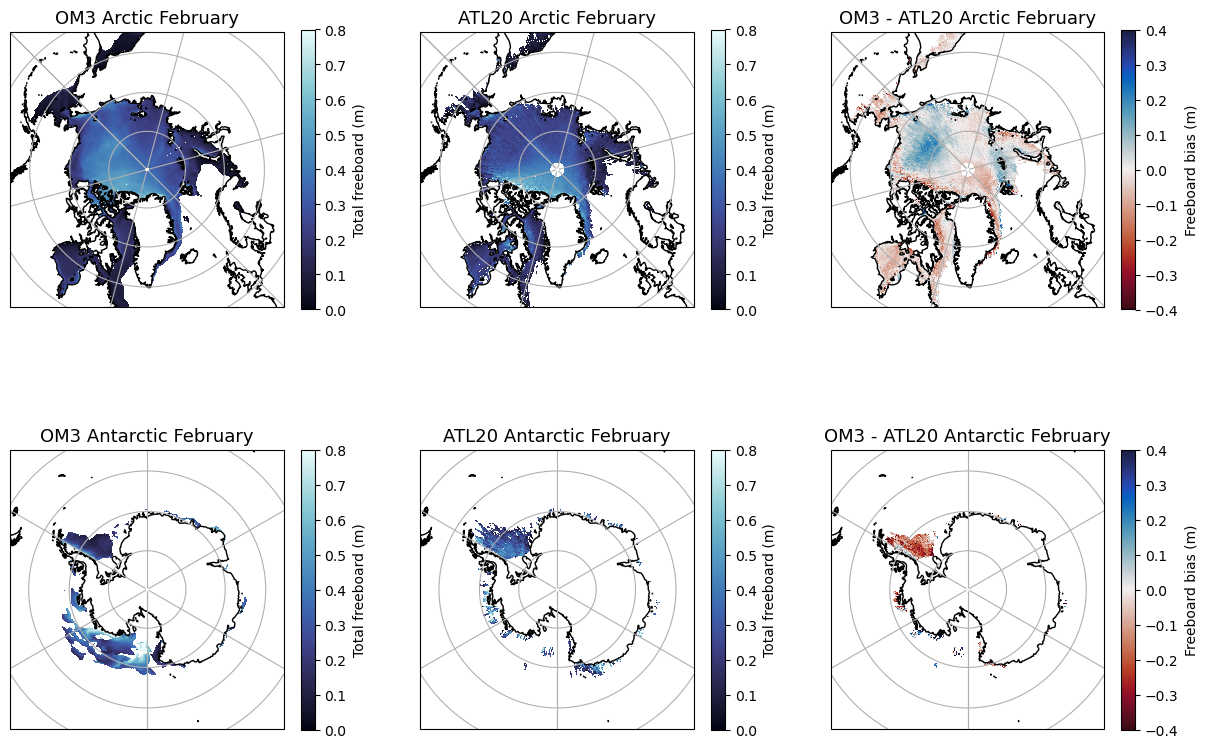

In [41]:
# Exact NSIDC polar-stereographic projections (EPSG:3411 North / EPSG:3412 South),
# matching the ATL20 grid_x / grid_y (as in SeaIce_area.ipynb)
polar_globe = ccrs.Globe(semimajor_axis=6378273, semiminor_axis=6356889.449)
nsidc_crs = {
    "Arctic": ccrs.Stereographic(central_latitude=90, central_longitude=-45, true_scale_latitude=70, globe=polar_globe),
    "Antarctic": ccrs.Stereographic(central_latitude=-90, central_longitude=0, true_scale_latitude=-70, globe=polar_globe),
}
nsidc_extent = {"Arctic": [-180, 180, 55, 90], "Antarctic": [-180, 180, -90, -55]}

fb_slice = clim_slice(freeboard_main, atl20_slice)

def plot_freeboard_maps(months):
    """OM3, ATL20 and OM3 - ATL20 total freeboard for the month of the year given for each hemisphere in `months`"""
    om3_freeboard, atl20_freeboard = freeboard_maps(months)
    fig = plt.figure(figsize=(15, 10))

    for row, region in enumerate(lat_range):
        crs = nsidc_crs[region]
        month = month_names[months[region]]
        panels = [
            (om3_freeboard[region], f"OM3 {region} {month}", cmo.ice, 0, 0.8, "Total freeboard (m)"),
            (atl20_freeboard[region], f"ATL20 {region} {month}", cmo.ice, 0, 0.8, "Total freeboard (m)"),
            # red where OM3 freeboard is too low, blue where too high
            (om3_freeboard[region] - atl20_freeboard[region], f"OM3 - ATL20 {region} {month}", cmo.balance_r, -0.4, 0.4, "Freeboard bias (m)"),
        ]
        for col, (data, title, cmap, vmin, vmax, cbar_label) in enumerate(panels):
            ax = fig.add_subplot(2, 3, 3 * row + col + 1, projection=crs)
            im = ax.pcolormesh(data.x, data.y, data, transform=crs, cmap=cmap, vmin=vmin, vmax=vmax)
            ax.set_extent(nsidc_extent[region], ccrs.PlateCarree())
            ax.coastlines()
            ax.gridlines()
            ax.set_title(title, font)
            plt.colorbar(im, ax=ax, shrink=0.8, label=cbar_label)

    when = f"{month_names[months['Arctic']]} (Arctic) and {month_names[months['Antarctic']]} (Antarctic)"
    mkmd.savefig(fig, f"{month_names[months['Arctic']]} / {month_names[months['Antarctic']]} Sea Ice Freeboard", f"Climatological {when} total freeboard (where ice concentration is at least 50%) for OM3 ({fb_slice.start}-{fb_slice.stop}) and ICESat-2 ATL20 ({atl20_slice.start}-{atl20_slice.stop}), and their difference. [GitHub issue: Sea-Ice Volume and Thickness](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/48)", dpi=150)
    plt.show()

plot_freeboard_maps(map_month)
plot_freeboard_maps(february)

## Ice volume tendency and freeboard bias

Does the freeboard bias line up with where the main OM3 run grows or loses ice? For March and September in each hemisphere, the climatological thermodynamic (`dvidtt`) and dynamic (`dvidtd`) ice volume tendencies (over the same years as the freeboard maps) are regridded onto the ATL20 grid and plotted against the freeboard bias (OM3 - ATL20) in each grid cell. ATL20 is least reliable in Arctic September, when melt ponds can bias it low.

In [42]:
tendency_names = {"dvidtt_m": "Thermodynamic", "dvidtd_m": "Dynamic"}
scatter_months = [3, 9]

tendencies = datastore.search(variable=list(tendency_names), frequency="1mon").to_dask(
    xarray_open_kwargs=dict(chunks={"ni": -1, "nj": -1}, decode_timedelta=True),
)[list(tendency_names)]
tendencies = tendencies.sel(time=clim_slice(tendencies, atl20_slice))
tendency_clim = tendencies.sel(time=tendencies.time.dt.month.isin(scatter_months)).groupby("time.month").mean("time").compute()

# month -> (region -> OM3 total freeboard, region -> ATL20 total freeboard), on the ATL20 grid
freeboard_by_month = {month: freeboard_maps({region: month for region in lat_range}) for month in scatter_months}

# month -> region -> ice volume tendencies on the ATL20 grid
tendency_by_month = {
    month: {region: atl20_regridders[region](tendency_clim.sel(month=month)).assign_coords(x=obs_ds.x, y=obs_ds.y).compute()
            for region, obs_ds in atl20.items()}
    for month in scatter_months
}

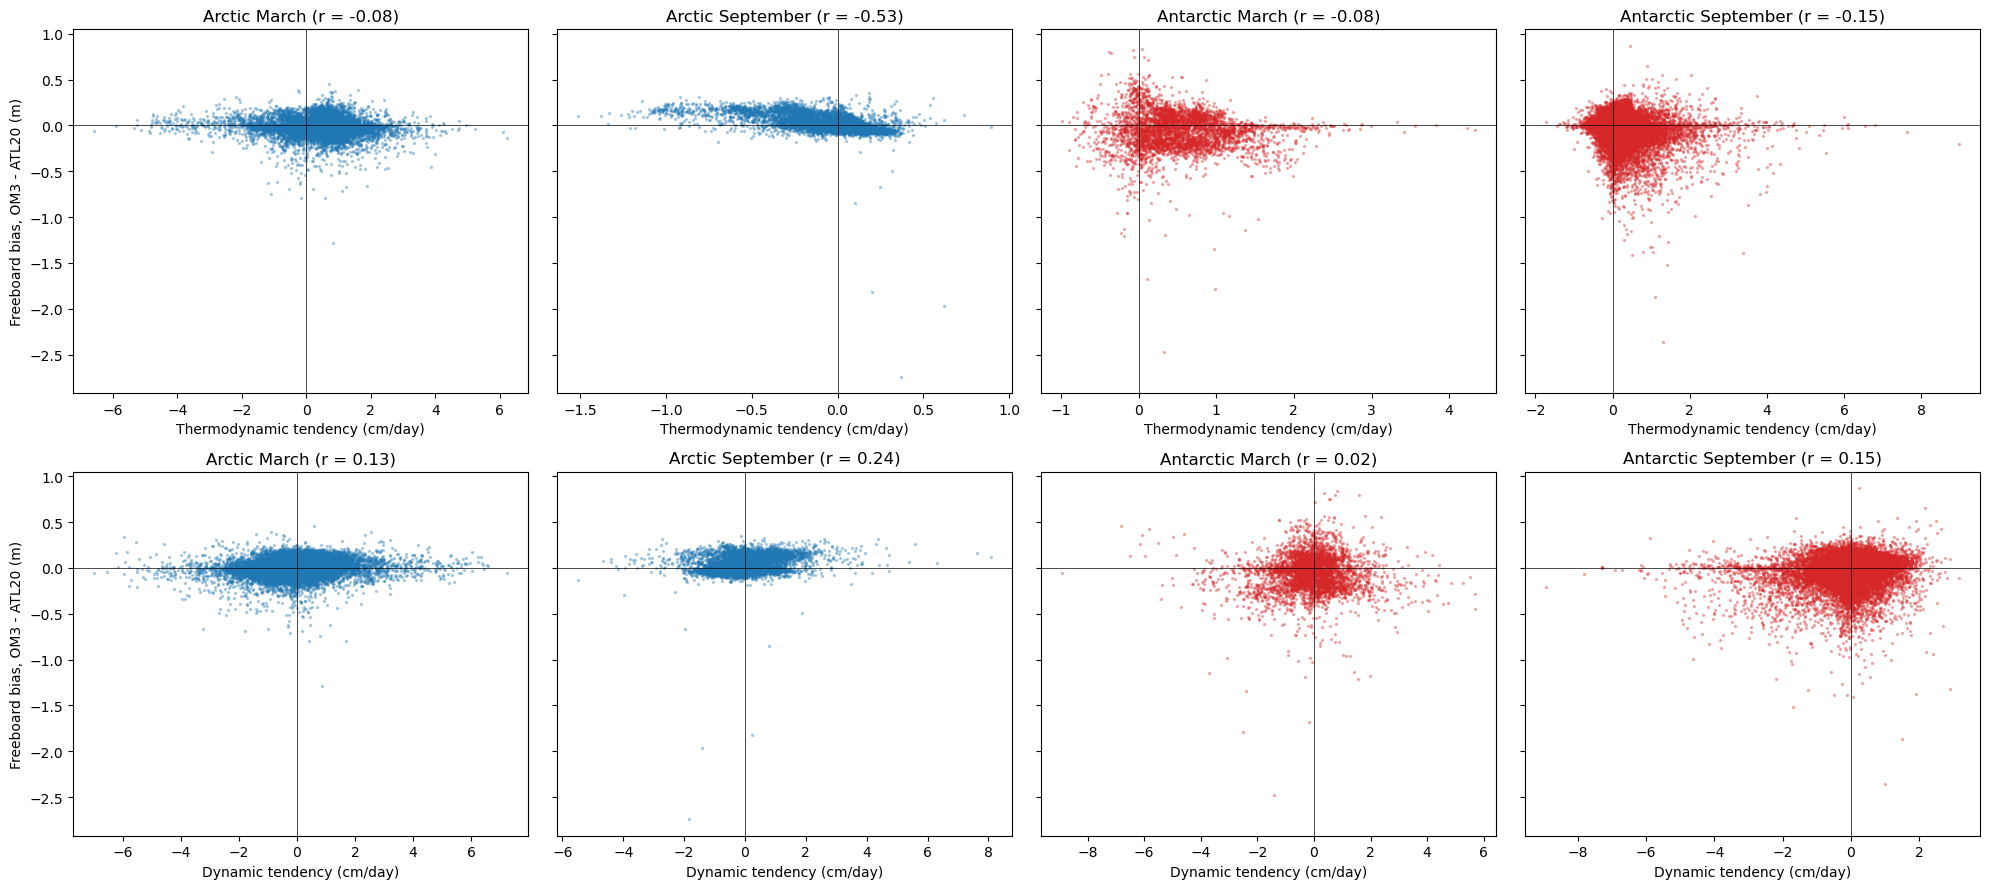

In [43]:
panels = [(region, month) for region in lat_range for month in scatter_months]
fig, axes = plt.subplots(len(tendency_names), len(panels), figsize=(5 * len(panels), 4.5 * len(tendency_names)), sharey=True)

for col, (region, month) in enumerate(panels):
    om3_freeboard, atl20_freeboard = freeboard_by_month[month]
    bias = (om3_freeboard[region] - atl20_freeboard[region]).values.ravel()
    for row, (var, name) in enumerate(tendency_names.items()):
        ax = axes[row, col]
        tendency = tendency_by_month[month][region][var].values.ravel()
        valid = np.isfinite(bias) & np.isfinite(tendency)
        ax.scatter(tendency[valid], bias[valid], s=2, alpha=0.3, color=region_colors[region])
        ax.axhline(0, color="k", lw=0.5)
        ax.axvline(0, color="k", lw=0.5)
        r = np.corrcoef(tendency[valid], bias[valid])[0, 1]
        ax.set_title(f"{region} {month_names[month]} (r = {r:.2f})")
        ax.set_xlabel(f"{name} tendency (cm/day)")
        if col == 0:
            ax.set_ylabel("Freeboard bias, OM3 - ATL20 (m)")

fig.tight_layout()

mkmd.savefig(fig, "Ice Volume Tendency and Freeboard Bias", f"Climatological March and September freeboard bias (OM3 - ICESat-2 ATL20) against the thermodynamic (dvidtt, top) and dynamic (dvidtd, bottom) ice volume tendency of the main OM3 run in each ATL20 grid cell ({fb_slice.start}-{fb_slice.stop}), with the correlation coefficient r. [GitHub issue: Sea-Ice Volume and Thickness](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/48)", dpi=150)
plt.show()

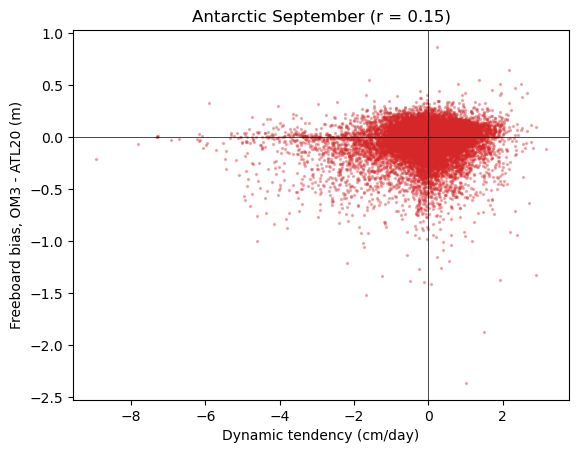

In [51]:
plt.figure()
ax = plt.axes()
ax.scatter(tendency[valid], bias[valid], s=2, alpha=0.3, color=region_colors[region])
ax.axhline(0, color="k", lw=0.5)
ax.axvline(0, color="k", lw=0.5)
r = np.corrcoef(tendency[valid], bias[valid])[0, 1]
ax.set_title(f"{region} {month_names[month]} (r = {r:.2f})")
ax.set_xlabel(f"{name} tendency (cm/day)")
ax.set_ylabel("Freeboard bias, OM3 - ATL20 (m)")

plt.show()

## Model sampled like ATL20

Each OM3 run's monthly freeboard over the ICESat-2 period, regridded onto the ATL20 grid as for the maps, and kept only where and when ATL20 has data. This removes differences in coverage between the model and ATL20 (cells within 25 km of the coast, months with no ICESat-2 tracks, cloud gaps), leaving differences in the freeboard itself. IAF runs only, as the model months need to match the observed months.

In [44]:
%%time
if IAF:
    # label -> {"Arctic": timeseries, "Antarctic": timeseries}, mean freeboard in m
    sampled_freeboards = {}
    for label, run_fb in run_freeboards.items():
        run_fb = run_fb.sel(time=slice("2018-10", None))
        # label model months mid-month, as for ATL20
        run_fb = run_fb.assign_coords(time=pd.to_datetime(run_fb.time.dt.strftime("%Y-%m-15")))
        sampled_freeboards[label] = {}
        for region, obs_ds in atl20.items():
            model_fb, obs_fb = xr.align(regrid_freeboard(run_fb, region), obs_ds.freeboard, join="inner")
            sampled_freeboards[label][region] = regional_mean(
                model_fb.where(obs_fb.notnull()), obs_ds.area, obs_ds.lat, region, ["y", "x"], atl20_lat_range
            ).compute()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 10.89 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
 

CPU times: user 32.6 s, sys: 42 s, total: 1min 14s
Wall time: 1min 1s


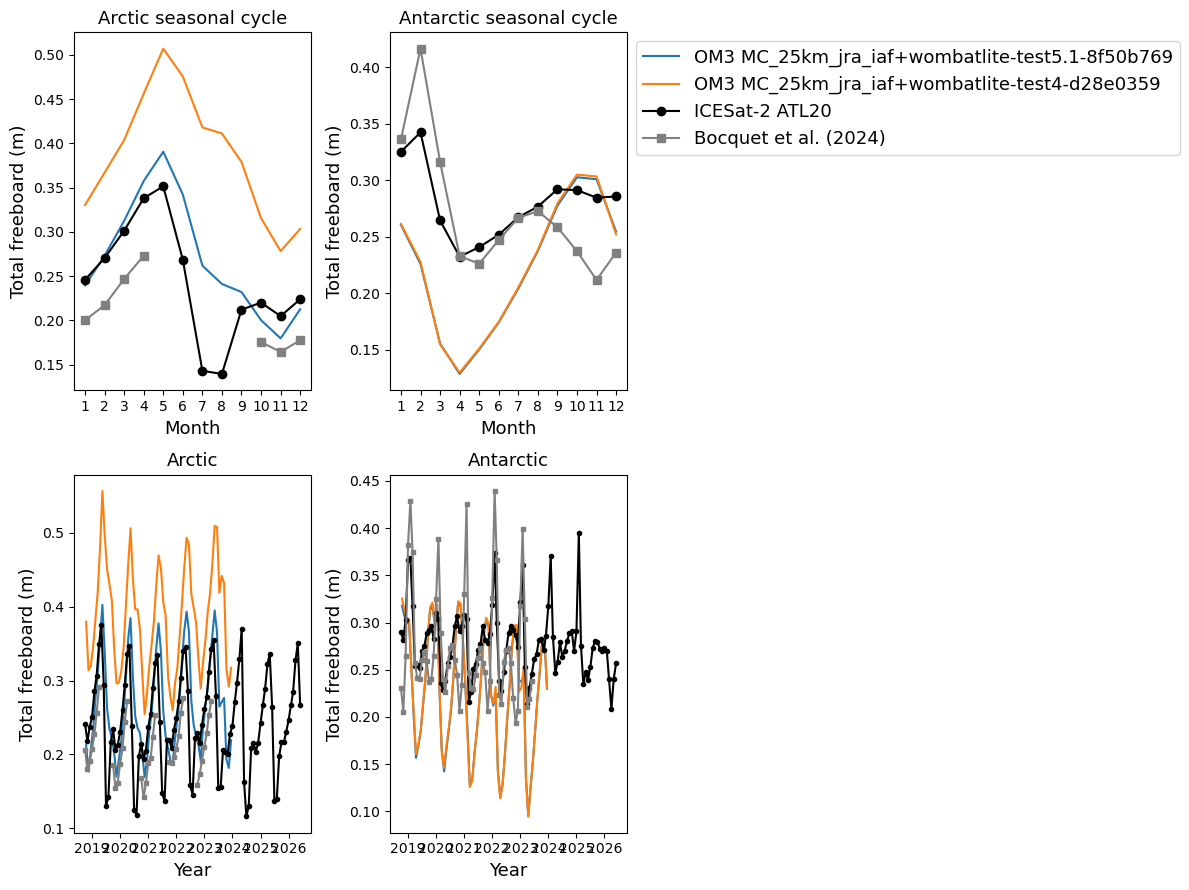

In [45]:
if IAF:
    plot_means([(sampled_freeboards, [atl20_obs, (bocquet_freeboards, bocquet_label, "0.5", "s")], "Total freeboard (m)")], "Sea Ice Freeboard sampled like ATL20", "Mean total (snow + ice) freeboard for OM3 runs regridded onto the ATL20 grid and sampled only where and when ICESat-2 ATL20 has data, compared with ATL20 and (not resampled, 50-81.5° latitude) Bocquet et al. (2024). Top: seasonal cycle. Bottom: monthly timeseries. [GitHub issue: Sea-Ice Volume and Thickness](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/48)")

In [46]:
client.close()

2026-10-30 15:05:23,634 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing
2026-10-30 15:05:23,636 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing
2026-10-30 15:05:23,641 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing
2026-10-30 15:05:23,646 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing
2026-10-30 15:05:23,677 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing
